# Bessel beam — non-diffracting propagation, self-healing, and an optical vortex
An ordinary focused beam spreads as it propagates: a Gaussian doubles its width
within a Rayleigh range. A **Bessel beam** does not. Its transverse profile — a
bright central core surrounded by concentric rings — is an exact propagation-
invariant solution of the wave equation: over an extended "non-diffracting" range
the core neither widens nor dims. This example launches a Bessel–Gauss beam into a
long air corridor and propagates it over ~100 wavelengths to show three things a
ray model cannot describe:

  1. **Non-diffracting core** — the Bessel core stays tight while a Gaussian of the
     same initial width (solved alongside) fans out by several-fold.
  2. **Self-healing** — an opaque obstacle placed on the axis casts a shadow that
     the surrounding rings refill downstream, so the core reconstructs itself a
     short distance past the block.
  3. **Optical vortex** — adding an azimuthal phase ramp exp(iℓθ) turns the core
     into a higher-order (vortex) Bessel beam: a doughnut intensity with a dark
     centre and a helical wavefront carrying orbital angular momentum.

How the beam is launched
------------------------
A Bessel beam is produced physically by an **axicon** (a shallow cone lens), which
imparts a radial linear phase so that conical wavefronts overlap on the axis over
an extended depth. We synthesize that input field directly at the source plane:

    E(r) = A(r) · exp(−i k_r r) · exp(i ℓ θ),   k_r = k₀ sin β,

with A(r) a smooth (Gaussian, edge-tapered) aperture, β the axicon cone angle, and
ℓ the topological charge (0 = ordinary Bessel, 1 = single-charge vortex). The
solver then propagates the real field; the core forms by interference and persists
over the geometric overlap length z_max ≈ A_radius / tan β.

Why a full-wave solver is required (and ray tracing is not enough)
------------------------------------------------------------------
The non-diffracting core, the ring structure, the self-healing, and the vortex
phase singularity are all interference effects of a field with a definite phase.
A ray tracer carries no phase, so it has no account of how a shadowed core refills
from the surrounding rings, nor of a dark line where the phase is undefined — it
simply cannot produce these results.

Physics / solver mode
---------------------
Scalar Helmholtz (one CW wavelength, linear, non-magnetic). Output is the
steady-state complex field; |field|² is the intensity and arg(field) the phase.

Geometry (propagation = X; transverse = Y, Z)
---------------------------------------------
A long air corridor. The structured field is launched on a Y–Z sheet just inside
the front boundary and propagates in +x. For the self-healing run an opaque
absorbing disk sits on the axis partway down. Open (absorbing) boundaries on all
six faces; the aperture is edge-tapered so it does not diffract off the walls.

Everything that sets the scene is a top-level variable so the example re-scales.

Outputs (saved in output/hmhz_bessel_vortex/)
--------------------------------------------------
  * bessel_nondiffracting.png — axial X–Y cuts: Bessel core (constant) vs a
    Gaussian of the same initial width (spreads);
  * bessel_selfhealing.png    — axial X–Y cut of the Bessel beam with the
    on-axis obstacle: the shadowed core reconstructs downstream;
  * bessel_transverse.png     — transverse |field| planes vs depth (intact
    rings → shadow behind the obstacle → reconstructed core);
  * bessel_onaxis.png         — on-axis intensity vs propagation distance for
    all three scalar beams (the non-diffracting plateau, the heal, the Gaussian roll-off);
  * bessel_vortex.png         — vortex beam: doughnut intensity, helical phase
    (the 2πℓ winding), and the dark non-diffracting core along the axis;
  * bessel_volume.npy / bessel_vortex_volume.npy — downsampled |field| volumes of
    the self-healing (obstacle) run and of the vortex run, for 3-D rendering.

The structured aperture and obstacle are built with NumPy.

Size: 4 solves, the largest 27.65 Mvoxel including boundaries, 0.62 GB of memory (service estimate).

In [1]:
from time import time

import numpy as np
import matplotlib.pyplot as plt
from matplotlib import colors

from wavesimpro import configure, simulate
from wsutils import output_dir

NAME = "hmhz_bessel_vortex"   # run name on the service and output folder
OUTPUT_DIR = output_dir(NAME)   # <repo root>/output/<NAME>
configure(description=NAME, folder=NAME)  # every solve goes in one folder

### Parameters

In [2]:
wavelength = 1.0           # Wavelength in micrometer (μm), in the air background (n = 1)
pixel_size = wavelength / 4  # Grid spacing in μm (~4 px/λ). The solver propagates through
#                              uniform air with an FFT-based (spectral) operator, so coarse
#                              sampling stays phase-accurate over long propagation; use λ/6
#                              for a finer run.

# Axicon cone: sets the Bessel transverse scale and the non-diffracting length.
sin_beta = 0.13            # sin of the axicon cone angle β (k_r = k₀ sin β)
charge = 1                 # vortex topological charge ℓ for the vortex run (0 = ordinary Bessel)

# Aperture / corridor.
w_env = 11.0               # Gaussian aperture radius at the source, μm (sets z_max ≈ w_env/tan β)
transverse = 48.0          # transverse extent in Y and Z, μm
x_end = 110.0              # corridor length along X, μm (≈ 110 λ of propagation)
x_src = 2.0                # source plane X, μm (just past the absorbing boundary)

# On-axis obstacle for the self-healing run (opaque absorbing disk).
x_obs = 30.0               # front face of the obstacle, μm. Placed just after the core has
#                            formed (~first 20 μm) and while it is still near peak, so the
#                            reconstructed core downstream lands well inside the strong part of
#                            the non-diffracting zone — the intensity recovery is then visible.
t_obs = 3.0                # obstacle thickness along X, μm
r_obs = 4.0                # obstacle radius, μm (> the Bessel core, so it fully blocks it)
n_obs = 1.0 + 0.3j         # index-matched absorber: opaque over t_obs (intensity transmission
#                            ~1e-5) but real index = air, so it barely reflects — this keeps the
#                            on-axis trace upstream clean instead of rippled by a standing wave.

vol_downsample = 2         # downsample factor for saved 3-D volumes

### Derived quantities

In [3]:
k0 = 2 * np.pi / wavelength
k_r = k0 * sin_beta                       # transverse wavenumber of the Bessel beam
tan_beta = np.tan(np.arcsin(sin_beta))
r_core = 2.405 / k_r                      # Bessel core radius (first J₀ zero), μm
core_fwhm = 2.26 / k_r                    # |J₀|² central-lobe FWHM, μm
w0_gauss = 1.92 / k_r                     # matched Gaussian waist (same central-lobe FWHM), μm
z_rayleigh = np.pi * w0_gauss ** 2 / wavelength  # Gaussian Rayleigh range, μm
z_max = w_env / tan_beta                  # Bessel non-diffracting length (estimate), μm
z_heal = r_obs / tan_beta                 # self-healing reconstruction distance (estimate), μm

n_size = (np.array([x_end, transverse, transverse]) / pixel_size).astype(int)
nx, ny, nz = (int(v) for v in n_size)
cy = cz = transverse / 2                  # optical axis (Y, Z centre), μm
iy_c, iz_c = ny // 2, nz // 2
ix_src = int(x_src / pixel_size)

print(f"Domain {x_end}x{transverse}x{transverse} μm = {nx}x{ny}x{nz} voxels "
      f"({nx * ny * nz / 1e6:.1f} Mvoxel without boundaries)")
print(f"Axicon β = {np.degrees(np.arcsin(sin_beta)):.2f}°; Bessel core radius {r_core:.2f} μm "
      f"(FWHM {core_fwhm:.2f} μm)")
print(f"Non-diffracting length z_max ≈ {z_max:.0f} μm = {z_max / wavelength:.0f} λ; "
      f"matched Gaussian waist {w0_gauss:.2f} μm (Rayleigh range {z_rayleigh:.0f} μm)")
print(f"Self-healing distance past the obstacle z_heal ≈ {z_heal:.0f} μm")

Domain 110.0x48.0x48.0 μm = 440x192x192 voxels (16.2 Mvoxel without boundaries)
Axicon β = 7.47°; Bessel core radius 2.94 μm (FWHM 2.77 μm)
Non-diffracting length z_max ≈ 84 μm = 84 λ; matched Gaussian waist 2.35 μm (Rayleigh range 17 μm)
Self-healing distance past the obstacle z_heal ≈ 31 μm


### Transverse coordinate grids at the source plane

In [4]:
_y = np.arange(ny) * pixel_size - cy
_z = np.arange(nz) * pixel_size - cz
_R, _Z = np.meshgrid(_y, _z, indexing="ij")     # (ny, nz)
_r = np.hypot(_R, _Z)
_theta = np.arctan2(_Z, _R)


def _edge_taper(r, margin=3.0):
    """Smooth cosine taper to zero over the last ``margin`` μm before the wall, so
    the aperture does not diffract off the absorbing boundary."""
    r_max = transverse / 2 - 1.0
    taper = np.ones_like(r)
    edge = (r > r_max - margin) & (r <= r_max)
    taper[edge] = 0.5 * (1 + np.cos(np.pi * (r[edge] - (r_max - margin)) / margin))
    taper[r > r_max] = 0.0
    return taper


def axicon_source(topological_charge=0):
    """Bessel–Gauss aperture: Gaussian envelope × axicon phase × optional vortex phase.

    Returns a scalar source (1, ny, nz) sheet and its (x, y, z) pixel position.
    """
    env = np.exp(-(_r / w_env) ** 2) * _edge_taper(_r)
    phase = -k_r * _r + topological_charge * _theta  # converging cone (+ helical ramp)
    field = (env * np.exp(1j * phase)).astype(np.complex64)
    return field[None, :, :], [ix_src, 0, 0]


def gaussian_source():
    """Matched Gaussian aperture (flat phase, waist w0_gauss) for the diffraction
    comparison. Same central-lobe width as the Bessel core at the source plane."""
    field = (np.exp(-(_r / w0_gauss) ** 2) * _edge_taper(_r)).astype(np.complex64)
    return field[None, :, :], [ix_src, 0, 0]


def air_permittivity():
    """Homogeneous air (n = 1) over the whole corridor."""
    return np.ones((nx, ny, nz), dtype=np.complex64)


def obstacle_permittivity():
    """Air corridor with an opaque absorbing disk on the axis (self-healing run)."""
    n = np.ones((nx, ny, nz), dtype=np.complex64)
    x = np.arange(nx) * pixel_size
    in_x = (x >= x_obs) & (x < x_obs + t_obs)  # 1-D mask along propagation
    disk = (_r <= r_obs)[None, :, :]           # (1, ny, nz), broadcast over the slab
    n[in_x] = np.where(disk, n_obs, n[in_x])
    return (n ** 2).astype(np.complex64)


def solve(permittivity, source):
    """Run one CW scalar Helmholtz solve and return the host-NumPy complex field."""
    values, position = source
    start = time()
    u, iterations, residual_norm = simulate(
        permittivity=permittivity,
        sources=[(values, position)],
        wavelength=wavelength,
        pixel_size=pixel_size,
        boundary_width=5.0,            # absorbing boundary width, μm (5 λ), open on all six faces
        periodic=(False, False, False),
    )
    print(f"  Time {time() - start:.1f} s; Iterations {iterations}; Residual {residual_norm:.2e}")
    return np.asarray(u)

### Run the four solves

In [5]:
air = air_permittivity()

print("\n[1/4] Bessel–Gauss beam (no obstacle)...")
u_bessel = solve(air, axicon_source(0))

print("[2/4] Bessel–Gauss beam with on-axis obstacle (self-healing)...")
u_heal = solve(obstacle_permittivity(), axicon_source(0))

print("[3/4] Matched Gaussian beam (diffraction comparison)...")
u_gauss = solve(air, gaussian_source())

print(f"[4/4] Vortex (charge ℓ = {charge}) Bessel beam...")
u_vortex = solve(air, axicon_source(charge))

amp_bessel = np.abs(u_bessel)
amp_heal = np.abs(u_heal)
amp_gauss = np.abs(u_gauss)
amp_vortex = np.abs(u_vortex)


[1/4] Bessel–Gauss beam (no obstacle)...

  ------------------------------------------------------
  Rayfos remote simulation
  ------------------------------------------------------
  Project   : 48759225-5ae9-4ead-bcb3-6ca9875c287e
  Version   : 7f313e93-6af9-4b32-810c-7affa69fc8ed
  Command   : 6a7a2296-1f92-496a-94d6-5833bcaacde3
  Mode      : Helmholtz (scalar)
  Domain    : 440x192x192 voxels  lambda=1.0 um  dx=0.250 um
  Engine    : Any (auto-select)  |  GPU: auto
  Threshold : 1.0e-06  max iter: 100000
  ------------------------------------------------------
  Time 82.6 s; Iterations 671; Residual 9.98e-07
[2/4] Bessel–Gauss beam with on-axis obstacle (self-healing)...

  ------------------------------------------------------
  Rayfos remote simulation
  ------------------------------------------------------
  Project   : 90ecb3cf-b254-479d-8973-e6ab05c3d69a
  Version   : 234e3f8a-e0e3-4e21-babd-4479233291ef
  Command   : 1c42801b-9c55-4699-866d-7673d28a7860
  Mode      : Helm

### Save downsampled volumes for 3-D rendering

In [6]:
ds = vol_downsample
np.save(f"{OUTPUT_DIR}/bessel_volume.npy", amp_heal[::ds, ::ds, ::ds].astype(np.float32))
np.save(f"{OUTPUT_DIR}/bessel_vortex_volume.npy", amp_vortex[::ds, ::ds, ::ds].astype(np.float32))
print(f"\nSaved downsampled |field| volumes ({amp_heal[::ds, ::ds, ::ds].shape}) to output/{NAME}/")


x_um = np.arange(nx) * pixel_size
extent_xy = [0, x_end, transverse, 0]          # x horizontal, y vertical (origin top)
extent_t = [0, transverse, transverse, 0]


Saved downsampled |field| volumes ((220, 96, 96)) to output/hmhz_bessel_vortex/

### Figure 1: non-diffracting Bessel vs diffracting Gaussian (axial cuts)

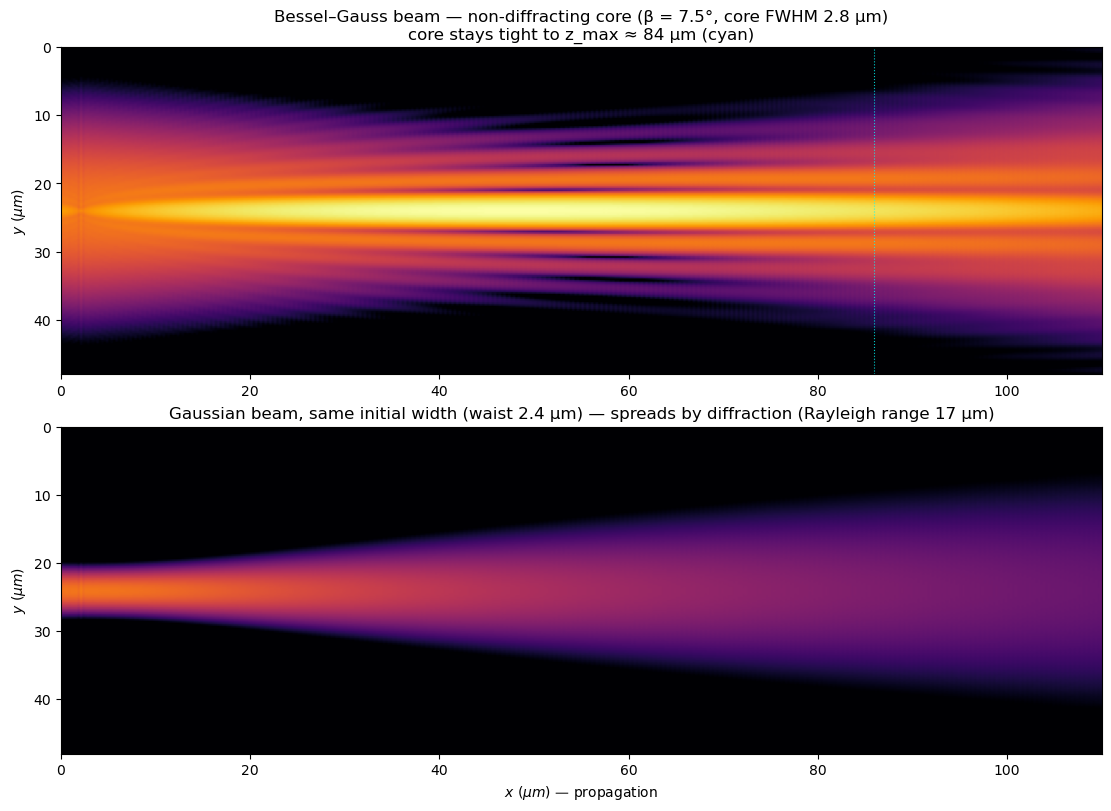

In [7]:
b_xy = amp_bessel[:, :, iz_c]
g_xy = amp_gauss[:, :, iz_c]
vmax = max(b_xy.max(), g_xy.max())
norm = colors.LogNorm(vmin=vmax * 1e-2, vmax=vmax)   # two decades shows the rings

fig, (ax0, ax1) = plt.subplots(2, 1, figsize=(11, 8), constrained_layout=True)
ax0.imshow(b_xy.T, cmap="inferno", extent=extent_xy, norm=norm, aspect="auto")
ax0.axvline(x_src + z_max, color="cyan", lw=0.8, ls=":", alpha=0.8)
ax0.set_title(f"Bessel–Gauss beam — non-diffracting core "
              f"(β = {np.degrees(np.arcsin(sin_beta)):.1f}°, core FWHM {core_fwhm:.1f} μm)\n"
              f"core stays tight to z_max ≈ {z_max:.0f} μm (cyan)")
ax0.set_ylabel(r"$y~(\mu m)$")

ax1.imshow(g_xy.T, cmap="inferno", extent=extent_xy, norm=norm, aspect="auto")
ax1.set_title(f"Gaussian beam, same initial width (waist {w0_gauss:.1f} μm) — "
              f"spreads by diffraction (Rayleigh range {z_rayleigh:.0f} μm)")
ax1.set_xlabel(r"$x~(\mu m)$ — propagation")
ax1.set_ylabel(r"$y~(\mu m)$")
fig.savefig(f"{OUTPUT_DIR}/bessel_nondiffracting.png", dpi=300, bbox_inches="tight")

### Figure 2: self-healing past the on-axis obstacle (axial cut)

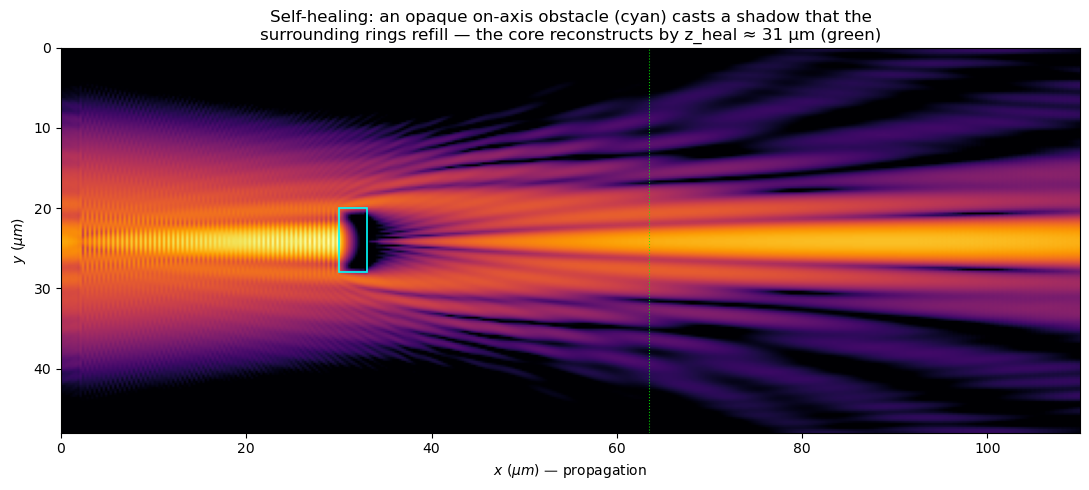

In [8]:
h_xy = amp_heal[:, :, iz_c]
hvmax = h_xy.max()
fig2, ax = plt.subplots(figsize=(11, 5))
ax.imshow(h_xy.T, cmap="inferno", extent=extent_xy,
          norm=colors.LogNorm(vmin=hvmax * 1e-2, vmax=hvmax), aspect="auto")
ax.add_patch(plt.Rectangle((x_obs, cy - r_obs), t_obs, 2 * r_obs,
                           fill=False, edgecolor="cyan", lw=1.2))
ax.axvline(x_obs + t_obs + z_heal, color="lime", lw=0.8, ls=":", alpha=0.8)
ax.set_title("Self-healing: an opaque on-axis obstacle (cyan) casts a shadow that the\n"
             f"surrounding rings refill — the core reconstructs by z_heal ≈ {z_heal:.0f} μm (green)")
ax.set_xlabel(r"$x~(\mu m)$ — propagation")
ax.set_ylabel(r"$y~(\mu m)$")
fig2.tight_layout()
fig2.savefig(f"{OUTPUT_DIR}/bessel_selfhealing.png", dpi=300, bbox_inches="tight")

### Figure 3: transverse planes vs depth (self-healing run)

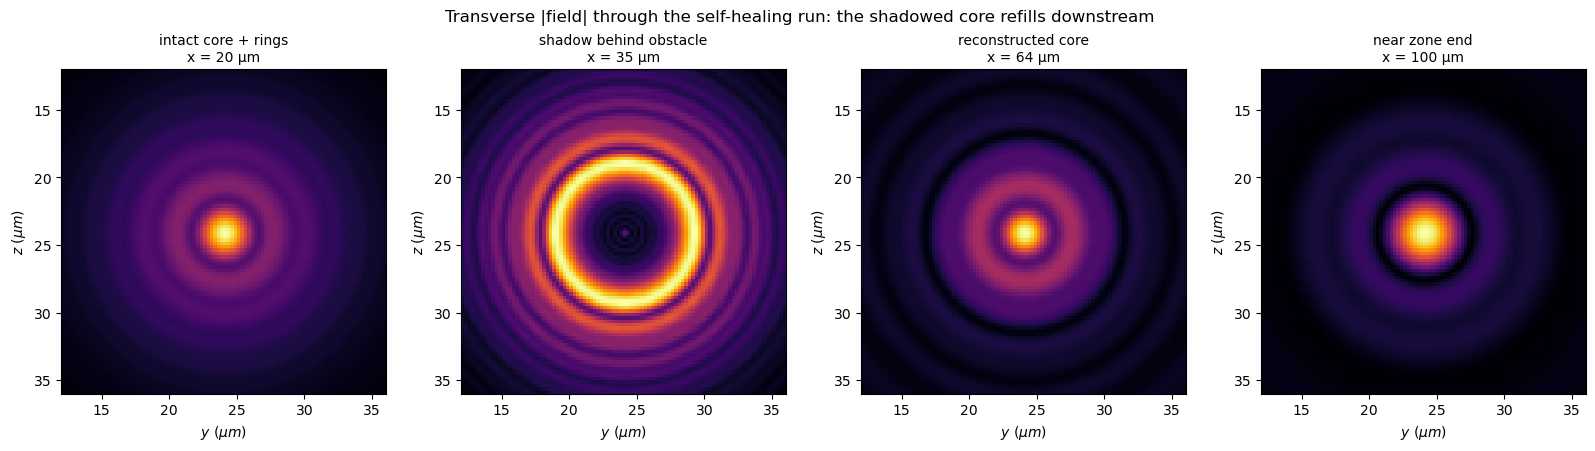

In [9]:
x_planes = [20.0, x_obs + t_obs + 2.0, x_obs + t_obs + z_heal, 100.0]
labels = ["intact core + rings", "shadow behind obstacle",
          "reconstructed core", "near zone end"]
fig3, axes = plt.subplots(1, 4, figsize=(16, 4.4), constrained_layout=True)
for ax, xp, lab in zip(axes, x_planes, labels):
    ix = int(xp / pixel_size)
    ax.imshow(amp_heal[ix, :, :].T, cmap="inferno", extent=extent_t, aspect="equal")
    ax.set_xlim(cy - 12, cy + 12)
    ax.set_ylim(cz + 12, cz - 12)
    ax.set_title(f"{lab}\nx = {xp:.0f} μm", fontsize=10)
    ax.set_xlabel(r"$y~(\mu m)$")
    ax.set_ylabel(r"$z~(\mu m)$")
fig3.suptitle("Transverse |field| through the self-healing run: the shadowed core refills downstream",
              fontsize=12)
fig3.savefig(f"{OUTPUT_DIR}/bessel_transverse.png", dpi=300, bbox_inches="tight")

### Figure 4: on-axis intensity vs propagation distance

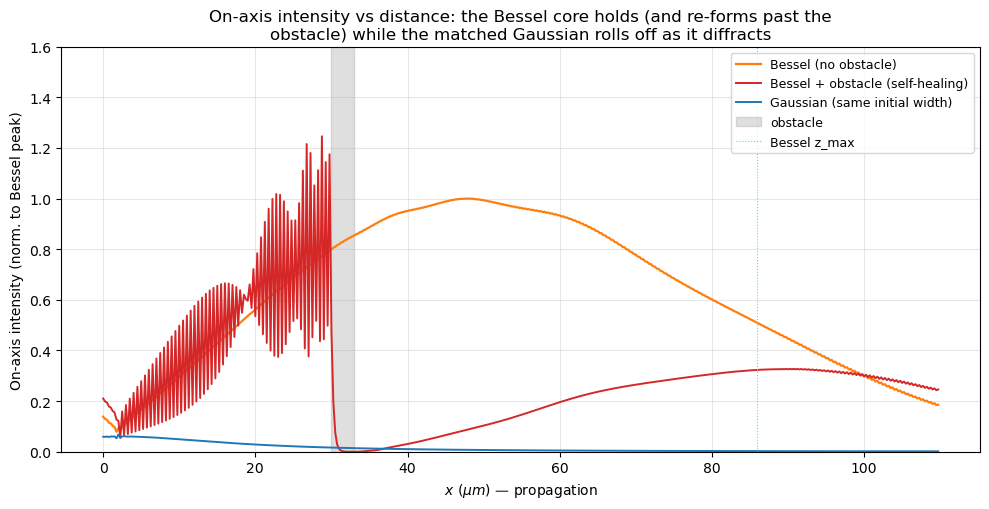

In [10]:
I_bessel = amp_bessel[:, iy_c, iz_c] ** 2
I_heal = amp_heal[:, iy_c, iz_c] ** 2
I_gauss = amp_gauss[:, iy_c, iz_c] ** 2
norm_I = I_bessel[ix_src + int(10 / pixel_size):].max()  # normalize to the Bessel peak

# Measured reconstruction: first x past the obstacle where the core recovers to
# half its pre-obstacle on-axis level.
pre = I_bessel[int((x_obs - 6) / pixel_size):int((x_obs - 1) / pixel_size)].mean()
ix_after = int((x_obs + t_obs) / pixel_size)
recovered = np.where(I_heal[ix_after:] >= 0.5 * pre)[0]
x_heal_meas = (ix_after + recovered[0]) * pixel_size if len(recovered) else np.nan

fig4, ax = plt.subplots(figsize=(10, 5.2))
ax.plot(x_um, I_bessel / norm_I, color="tab:orange", lw=1.6, label="Bessel (no obstacle)")
ax.plot(x_um, I_heal / norm_I, color="tab:red", lw=1.4, label="Bessel + obstacle (self-healing)")
ax.plot(x_um, I_gauss / norm_I, color="tab:blue", lw=1.4, label="Gaussian (same initial width)")
ax.axvspan(x_obs, x_obs + t_obs, color="grey", alpha=0.25, label="obstacle")
ax.axvline(x_src + z_max, color="cyan", lw=0.8, ls=":", label="Bessel z_max")
if np.isfinite(x_heal_meas):
    ax.axvline(x_heal_meas, color="green", lw=0.8, ls="--",
               label=f"core recovered (x ≈ {x_heal_meas:.0f} μm)")
ax.set_xlabel(r"$x~(\mu m)$ — propagation")
ax.set_ylabel("On-axis intensity (norm. to Bessel peak)")
ax.set_title("On-axis intensity vs distance: the Bessel core holds (and re-forms past the\n"
             "obstacle) while the matched Gaussian rolls off as it diffracts")
ax.set_ylim(0, 1.6)
ax.grid(True, alpha=0.3)
ax.legend(fontsize=9, loc="upper right")
fig4.tight_layout()
fig4.savefig(f"{OUTPUT_DIR}/bessel_onaxis.png", dpi=300, bbox_inches="tight")

### Figure 5: optical vortex (doughnut intensity + helical phase)

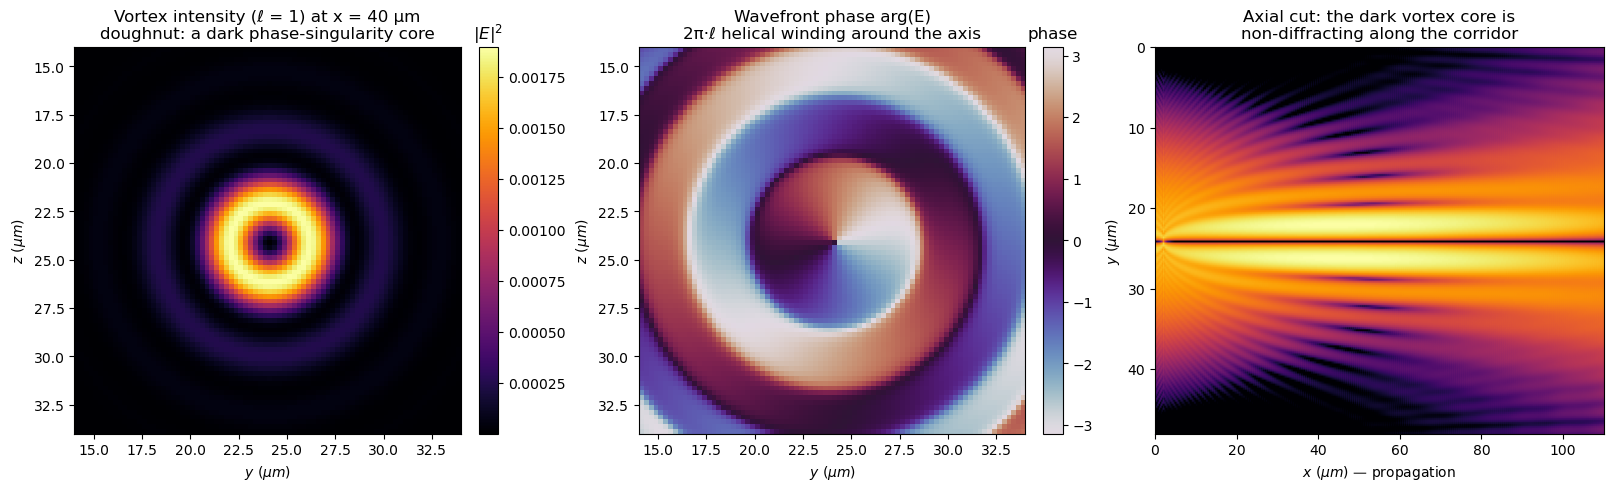

In [11]:
x_mid = 40.0
ix_mid = int(x_mid / pixel_size)
v_int = amp_vortex[ix_mid, :, :] ** 2
v_phase = np.angle(u_vortex[ix_mid, :, :])
v_xy = amp_vortex[:, :, iz_c]
vvmax = v_xy.max()

fig5, (axa, axb, axc) = plt.subplots(1, 3, figsize=(16, 4.8), constrained_layout=True)

ima = axa.imshow(v_int.T, cmap="inferno", extent=extent_t, aspect="equal")
axa.set_xlim(cy - 10, cy + 10)
axa.set_ylim(cz + 10, cz - 10)
axa.set_title(f"Vortex intensity (ℓ = {charge}) at x = {x_mid:.0f} μm\n"
              "doughnut: a dark phase-singularity core")
axa.set_xlabel(r"$y~(\mu m)$")
axa.set_ylabel(r"$z~(\mu m)$")
fig5.colorbar(ima, ax=axa, fraction=0.046, pad=0.04).ax.set_title(r"$|E|^2$")

imb = axb.imshow(v_phase.T, cmap="twilight", extent=extent_t, aspect="equal",
                 vmin=-np.pi, vmax=np.pi)
axb.set_xlim(cy - 10, cy + 10)
axb.set_ylim(cz + 10, cz - 10)
axb.set_title(f"Wavefront phase arg(E)\n2π·ℓ helical winding around the axis")
axb.set_xlabel(r"$y~(\mu m)$")
axb.set_ylabel(r"$z~(\mu m)$")
fig5.colorbar(imb, ax=axb, fraction=0.046, pad=0.04).ax.set_title("phase")

axc.imshow(v_xy.T, cmap="inferno", extent=extent_xy,
           norm=colors.LogNorm(vmin=vvmax * 1e-2, vmax=vvmax), aspect="auto")
axc.set_title("Axial cut: the dark vortex core is\nnon-diffracting along the corridor")
axc.set_xlabel(r"$x~(\mu m)$ — propagation")
axc.set_ylabel(r"$y~(\mu m)$")
fig5.savefig(f"{OUTPUT_DIR}/bessel_vortex.png", dpi=300, bbox_inches="tight")

### Report

In [12]:
print(f"\nSelf-healing: core recovered to half the pre-obstacle level at x ≈ "
      f"{x_heal_meas:.0f} μm (estimate {x_obs + t_obs + z_heal:.0f} μm)")
gauss_fall = I_gauss[int((x_src + z_max) / pixel_size)] / norm_I
print(f"At x = z_max, on-axis intensity: Bessel ≈ {I_bessel[int((x_src + z_max) / pixel_size)] / norm_I:.2f}, "
      f"Gaussian ≈ {gauss_fall:.2f} (of the Bessel plateau)")
print(f"Saved bessel_nondiffracting.png, bessel_selfhealing.png, bessel_transverse.png, "
      f"bessel_onaxis.png, bessel_vortex.png to output/{NAME}/")

plt.show()


Self-healing: core recovered to half the pre-obstacle level at x ≈ nan μm (estimate 64 μm)
At x = z_max, on-axis intensity: Bessel ≈ 0.51, Gaussian ≈ 0.00 (of the Bessel plateau)
Saved bessel_nondiffracting.png, bessel_selfhealing.png, bessel_transverse.png, bessel_onaxis.png, bessel_vortex.png to output/hmhz_bessel_vortex/
